___
<a href='https://honglab.ai'><p style="text-align:center;"><img src='https://lh3.googleusercontent.com/lY3ySXooSmwsq5r-mRi7uiypbo0Vez6pmNoQxMFhl9fmZJkRHu5lO2vo7se_0YOzgmDyJif9fi4_z0o3ZFdwd8NVSWG6Ea80uWaf3pOHpR4GHGDV7kaFeuHR3yAjIJjDgfXMxsvw=w2400'  class="center" width="50%" height="50%"/></p></a>
___
<center><em>Content Copyright by HongLab, Inc.</em></center>

# 어텐션 계산

**해당 강의:** 파트3 챕터5 「트랜스포머의 구조」 · 「현대적 레시피」

여기서는 트랜스포머 블록 가운데 어텐션 부분만 떼어 내 집중해서 봅니다.
RMSNorm·SwiGLU 같은 나머지 부품, 전체 모델 조립, 훈련은 `03_작은GPT만들기`에서 다룹니다.

토큰 다섯 개짜리 작은 텐서로 어텐션을 한 단계씩 계산합니다.
Q·K·V 만들기, 점수 매기기, 인과 마스크, softmax, V 가중합, 멀티헤드 순서로 진행합니다.
마지막으로 어텐션만으로는 단어 순서를 구분하지 못한다는 것을 확인하고, RoPE로 위치 정보를 넣어 봅니다.

- 실행 시간: 몇 초 (CPU)
- 설치할 것: torch, matplotlib

In [2]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 그래프에 한글이 보이도록 설치된 한글 폰트를 찾아 씁니다 (윈도우·맥·리눅스 순)
installed = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in installed:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False

import math
import torch
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_printoptions(precision=2, sci_mode=False)

## 입력 — 토큰 다섯 개

강의 예시처럼 「아이가 사과를 깨끗이 씻어서 그것을」 다섯 토큰을 씁니다. 토큰마다 벡터가 하나씩 있습니다.
강의에서는 벡터 크기가 512였는데, 여기서는 눈으로 볼 수 있게 8로 줄였습니다.
값은 무작위라서 뜻은 없습니다. 계산 과정과 텐서 모양만 봅니다.

In [3]:
words = ["아이가", "사과를", "깨끗이", "씻어서", "그것을"]
T, C = len(words), 8                 # 토큰 수, 벡터 크기
x = torch.randn(T, C)
print("x 모양:", tuple(x.shape))     # (T, C)
print(x)

x 모양: (5, 8)
tensor([[-1.13, -1.15, -0.25, -0.43,  0.85,  0.69, -0.32, -2.12],
        [ 0.32, -1.26,  0.35,  0.31,  0.12,  1.24,  1.12, -0.25],
        [-1.35, -1.70,  0.57,  0.79,  0.60, -1.56, -0.34,  1.85],
        [-0.22, -0.74,  0.56,  0.26, -0.17, -0.68,  0.94,  0.49],
        [ 1.20,  0.08, -1.20, -0.00, -0.52, -0.31, -1.58,  1.71]])


## Q·K·V 만들기

입력에 가중치 행렬 세 개를 각각 곱하면 Q(질의), K(키), V(값)가 나옵니다.
실제 모델에서는 이 행렬들이 훈련으로 정해집니다. 여기서는 무작위로 채웁니다.

In [3]:
Wq, Wk, Wv = (torch.randn(C, C) / math.sqrt(C) for _ in range(3))
q, k, v = x @ Wq, x @ Wk, x @ Wv
print("q·k·v 모양:", tuple(q.shape), tuple(k.shape), tuple(v.shape))

q·k·v 모양: (5, 8) (5, 8) (5, 8)


「파이토치 구현」 강의에서 본 것처럼 실제 코드에서는 세 행렬을 하나(`wqkv`)로 붙여 한 번에 곱하고, 결과를 셋으로 자릅니다. 결과는 똑같습니다.

In [4]:
Wqkv = torch.cat([Wq, Wk, Wv], dim=1)            # (C, 3C)
q2, k2, v2 = (x @ Wqkv).split(C, dim=-1)
print("따로 곱한 결과와 같은가:", torch.allclose(q, q2), torch.allclose(k, k2), torch.allclose(v, v2))

따로 곱한 결과와 같은가: True True True


## 점수 — Q와 K의 내적

각 토큰의 Q를 모든 토큰의 K와 내적하면 T×T 점수표가 나옵니다. 가로줄은 보는 토큰, 세로줄은 보이는 토큰입니다.
점수는 벡터 크기 d의 제곱근으로 나눕니다(스케일드 닷 프로덕트).

In [5]:
def show_table(m, rows=words, cols=words):
    print(" " * 8 + "".join(f"{c:>8}" for c in cols))
    for r, line in zip(rows, m):
        print(f"{r:>6}  " + "".join(f"{v:>8.2f}" for v in line.tolist()))

scores = q @ k.T / math.sqrt(C)
show_table(scores)

             아이가     사과를     깨끗이     씻어서     그것을
   아이가      1.26    0.30   -0.53   -0.11   -1.23
   사과를      0.39    0.46   -0.36    0.03   -0.15
   깨끗이     -1.12   -0.61   -0.26   -0.59    1.40
   씻어서     -0.90   -0.08   -0.44   -0.14    0.73
   그것을     -0.55   -0.66    1.21   -0.20    1.20


왜 제곱근으로 나눌까요? 벡터가 길어질수록 내적값이 커지고, 큰 점수를 softmax에 넣으면 한 칸만 거의 1이 되고 나머지는 0이 됩니다.
그러면 여러 토큰을 골고루 섞지 못하고 학습도 불안정해집니다. 강의의 헤드 크기 64로 확인해 봅니다.

In [6]:
d = 64
dots = (torch.randn(10_000, d) * torch.randn(10_000, d)).sum(-1)
print(f"64차원 내적의 표준편차: {dots.std():.1f}  →  √64 = 8로 나누면 {(dots / 8).std():.1f}")

# 키 다섯 개에 대한 점수를 1,000번 만들어, softmax 뒤 가장 큰 칸이 가져가는 비율을 평균 냅니다
s = (torch.randn(1000, 1, d) * torch.randn(1000, 5, d)).sum(-1)
print(f"가장 큰 칸의 비율(평균): 나누기 전 {s.softmax(-1).max(-1).values.mean():.0%}"
      f" → 8로 나눈 뒤 {(s / 8).softmax(-1).max(-1).values.mean():.0%}")
print("예시 한 줄 — 나누기 전:", s[0].softmax(-1))
print("예시 한 줄 — 나눈 뒤:  ", (s[0] / 8).softmax(-1))

64차원 내적의 표준편차: 8.1  →  √64 = 8로 나누면 1.0
가장 큰 칸의 비율(평균): 나누기 전 90% → 8로 나눈 뒤 46%
예시 한 줄 — 나누기 전: tensor([0.97, 0.03, 0.00, 0.00, 0.00])
예시 한 줄 — 나눈 뒤:   tensor([0.55, 0.36, 0.04, 0.02, 0.03])


## 인과 마스크

GPT는 아직 만들지 않은 미래 토큰을 보면 안 됩니다. 점수표의 오른쪽 위(미래)를 −∞로 채운 마스크를 더합니다.
0이 아니라 −∞를 쓰는 이유는 softmax를 지나면 정확히 0이 되기 때문입니다.

In [7]:
mask = torch.triu(torch.full((T, T), float("-inf")), diagonal=1)   # 위 삼각만 −∞, 나머지 0
print(mask)
masked = scores + mask
show_table(masked)

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])
             아이가     사과를     깨끗이     씻어서     그것을
   아이가      1.26    -inf    -inf    -inf    -inf
   사과를      0.39    0.46    -inf    -inf    -inf
   깨끗이     -1.12   -0.61   -0.26    -inf    -inf
   씻어서     -0.90   -0.08   -0.44   -0.14    -inf
   그것을     -0.55   -0.66    1.21   -0.20    1.20


## softmax — 가로줄 합은 1

가로줄마다 softmax를 적용하면, 볼 수 있는 칸에 나눠 준 비율(어텐션 가중치)이 됩니다. 줄마다 합이 1입니다.

             아이가     사과를     깨끗이     씻어서     그것을
   아이가      1.00    0.00    0.00    0.00    0.00
   사과를      0.48    0.52    0.00    0.00    0.00
   깨끗이      0.20    0.33    0.47    0.00    0.00
   씻어서      0.14    0.32    0.23    0.31    0.00
   그것을      0.07    0.06    0.39    0.10    0.39
가로줄 합: tensor([1.00, 1.00, 1.00, 1.00, 1.00])


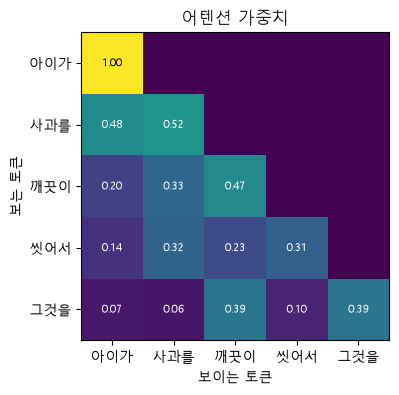

In [8]:
weights = masked.softmax(dim=-1)
show_table(weights)
print("가로줄 합:", weights.sum(-1))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(weights, cmap="viridis")
ax.set_xticks(range(T), words)
ax.set_yticks(range(T), words)
ax.set_xlabel("보이는 토큰")
ax.set_ylabel("보는 토큰")
ax.set_title("어텐션 가중치")
for i in range(T):
    for j in range(i + 1):
        ax.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="k" if weights[i, j] > 0.6 else "w")
plt.show()

## 가중합 — 골라 오지 않고 섞는다

가중치로 V를 섞으면 어텐션 출력이 나옵니다. 마지막 토큰 「그것을」의 출력은 다섯 V를 가중치만큼 더한 것입니다.

In [9]:
out = weights @ v                                  # (T, T) @ (T, C) → (T, C)
print("출력 모양:", tuple(out.shape))

last = sum(weights[4, j] * v[j] for j in range(T))
print("「그것을」 출력을 직접 더한 값과 같은가:", torch.allclose(out[4], last, atol=1e-6))

출력 모양: (5, 8)
「그것을」 출력을 직접 더한 값과 같은가: True


지금까지 한 계산을 파이토치는 함수 하나(`F.scaled_dot_product_attention`)로 제공합니다. 실습 자료의 코드도 이 함수를 씁니다.
배치(B)와 헤드(H) 차원이 앞에 있어야 해서 `[None, None]`으로 차원을 두 개 붙여 넣습니다.

In [10]:
ref = F.scaled_dot_product_attention(q[None, None], k[None, None], v[None, None], is_causal=True)[0, 0]
print("직접 계산한 결과와 같은가:", torch.allclose(out, ref, atol=1e-6))

직접 계산한 결과와 같은가: True


## 멀티헤드 — 여러 관점으로 동시에

벡터 8칸을 4칸짜리 두 묶음으로 나눠, 헤드마다 따로 어텐션을 계산합니다.
데이터를 복사하는 것이 아니라 보는 방식만 바꿉니다(`view`).
강의의 512칸·8헤드도 같은 방식으로 64칸씩 나눕니다.

헤드로 나눈 q 모양: (2, 5, 4)
헤드를 이어 붙인 출력 모양: (5, 8)


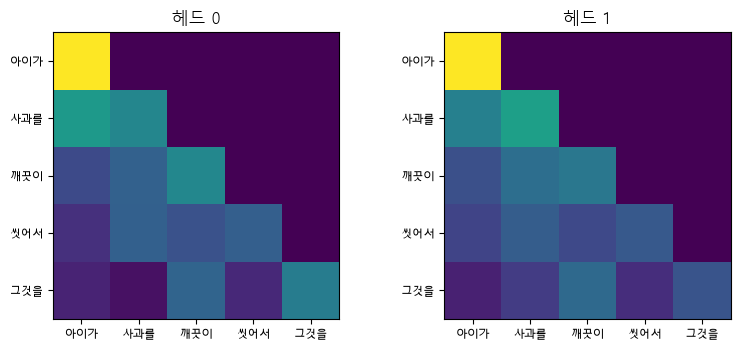

In [11]:
H = 2
hd = C // H                                        # 헤드 하나의 크기
qh = q.view(T, H, hd).transpose(0, 1)              # (T, C) → (T, H, hd) → (H, T, hd)
kh = k.view(T, H, hd).transpose(0, 1)
vh = v.view(T, H, hd).transpose(0, 1)
print("헤드로 나눈 q 모양:", tuple(qh.shape))

wh = (qh @ kh.transpose(-2, -1) / math.sqrt(hd) + mask).softmax(-1)   # (H, T, T)
yh = wh @ vh                                                          # (H, T, hd)
y = yh.transpose(0, 1).reshape(T, C)               # 헤드를 다시 이어 붙여 (T, C)
print("헤드를 이어 붙인 출력 모양:", tuple(y.shape))

fig, axes = plt.subplots(1, H, figsize=(8, 3.6))
for h, ax in enumerate(axes):
    ax.imshow(wh[h], cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(T), words, fontsize=8)
    ax.set_yticks(range(T), words, fontsize=8)
    ax.set_title(f"헤드 {h}")
plt.tight_layout()
plt.show()

같은 입력이라도 헤드마다 Q·K의 다른 칸을 쓰므로 가중치가 다르게 나옵니다. 지금은 가중치 행렬이 무작위라 차이가 작습니다. 훈련된 모델에서는 헤드마다 보는 곳이 뚜렷이 갈립니다(03 노트북 끝에서 확인합니다).
이어 붙인 뒤에는 행렬(`wo`)을 하나 더 곱해 헤드들의 결과를 섞습니다.

실제 코드에서는 앞에 배치 차원이 붙어서 `(B, T, C)`를 `(B, H, T, hd)`로 바꿉니다. 계산은 같습니다.

## 어텐션은 단어 순서를 모른다

마스크를 빼고 어텐션만 계산해 봅니다. 그다음 다섯 토큰의 순서를 섞어 다시 계산합니다.

In [12]:
def attention_no_mask(x):
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    return (q @ k.T / math.sqrt(C)).softmax(-1) @ v

perm = [4, 2, 0, 3, 1]                             # 순서를 섞는다
print("섞은 순서:", [words[i] for i in perm])

out_orig = attention_no_mask(x)
out_perm = attention_no_mask(x[perm])
print("섞은 입력의 출력 = 원래 출력을 같은 순서로 섞은 것:", torch.allclose(out_perm, out_orig[perm], atol=1e-6))

섞은 순서: ['그것을', '깨끗이', '아이가', '씻어서', '사과를']
섞은 입력의 출력 = 원래 출력을 같은 순서로 섞은 것: True


순서를 섞어도 토큰마다 나오는 벡터는 그대로이고 자리만 바뀝니다. 어텐션은 토큰들을 「순서 없는 묶음」으로 봅니다.
그래서 위치 정보를 따로 넣어야 합니다. 요즘 모델이 쓰는 방법이 RoPE입니다.

## RoPE — 위치만큼 돌린다

RoPE는 Q와 K의 숫자를 두 개씩 짝지어, 토큰 위치에 비례하는 각도만큼 돌립니다. 짝마다 도는 속도가 다릅니다.
아래 코드는 실습 자료의 `src/model.py`와 같은 방식입니다.

In [13]:
def rope_tables(head_dim, max_len, theta=10000.0):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))   # 짝마다 도는 속도
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)                   # (위치, 짝)
    emb = torch.cat((angles, angles), dim=-1)
    return emb.cos(), emb.sin()

def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

cos, sin = rope_tables(C, 64)
angles = torch.outer(torch.arange(4).float(), 1.0 / (10000 ** (torch.arange(0, C, 2).float() / C)))
for j in range(C // 2):
    print(f"짝 {j}: 위치 0–3의 각도(라디안)", [round(a, 3) for a in angles[:, j].tolist()])

짝 0: 위치 0–3의 각도(라디안)

 [0.0, 1.0, 2.0, 3.0]
짝 1: 위치 0–3의 각도(라디안) [0.0, 0.1, 0.2, 0.3]
짝 2: 위치 0–3의 각도(라디안) [0.0, 0.01, 0.02, 0.03]
짝 3: 위치 0–3의 각도(라디안) [0.0, 0.001, 0.002, 0.003]


짝 0은 위치가 하나 늘 때마다 1라디안씩 빠르게 돌고, 뒤쪽 짝일수록 느리게 돕니다. 강의의 「여러 속도로 도는 바늘」입니다.

같은 q와 k를 여러 위치에 놓고 점수를 재 봅니다. 두 토큰의 거리가 같으면, 절대 위치가 달라도 점수가 같습니다.
각도의 차이가 곧 상대 거리이기 때문입니다.

In [14]:
q1, k1 = torch.randn(C), torch.randn(C)

def score_at(m, n):
    qm = apply_rope(q1, cos[m], sin[m])            # q를 m번째 자리에
    kn = apply_rope(k1, cos[n], sin[n])            # k를 n번째 자리에
    return (qm @ kn).item()

for m, n in [(3, 0), (8, 5), (40, 37), (3, 2), (3, 1)]:
    print(f"q 위치 {m:>2}, k 위치 {n:>2} (거리 {m - n}): 점수 {score_at(m, n):6.3f}")

q 위치  3, k 위치  0 (거리 3): 점수  2.215
q 위치  8, k 위치  5 (거리 3): 점수  2.215
q 위치 40, k 위치 37 (거리 3): 점수  2.215
q 위치  3, k 위치  2 (거리 1): 점수  3.562
q 위치  3, k 위치  1 (거리 2): 점수  5.820


이제 RoPE를 넣고 다시 순서를 섞어 봅니다. 이번에는 결과가 달라집니다. 어텐션이 위치를 구분하게 되었습니다.

In [15]:
def attention_rope(x):
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    q, k = apply_rope(q, cos[:T], sin[:T]), apply_rope(k, cos[:T], sin[:T])
    return (q @ k.T / math.sqrt(C)).softmax(-1) @ v

out_orig = attention_rope(x)
out_perm = attention_rope(x[perm])
print("RoPE를 넣으면 섞기 전과 같은가:", torch.allclose(out_perm, out_orig[perm], atol=1e-6))

RoPE를 넣으면 섞기 전과 같은가: False


## 정리

- 어텐션은 Q와 K로 점수를 매기고, softmax로 비율을 정해, V를 그 비율대로 섞습니다.
- 인과 마스크는 미래 칸을 −∞로 가려 softmax 뒤 0이 되게 합니다.
- 멀티헤드는 벡터를 나눠 헤드마다 따로 어텐션을 계산한 뒤 다시 이어 붙입니다.
- 어텐션 자체는 순서를 모르기 때문에 RoPE로 Q와 K를 위치만큼 돌려 위치를 넣습니다.

다음 노트북에서는 텍스트를 토큰으로 나누는 BPE 토크나이저를 만듭니다.